In [1]:
import os, glob, random
import numpy as np
import pandas as pd
import torch

# Reproducibility: fix every source of randomness
SEED = 42
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed(SEED)

# Paths
BASE = "/kaggle/input/datasets/khlafalshammari/competition"
TRAIN_DIR = os.path.join(BASE, "train", "train")
TEST_DIR = os.path.join(BASE, "test", "test")

# Find the cleaned metadata produced by notebook 01
meta_path = glob.glob("/kaggle/input/**/train_metadata_clean.csv", recursive=True)
print("Metadata found at:", meta_path)

# Check the GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

Metadata found at: ['/kaggle/input/notebooks/khlafalshammari/01-eda-facial-features/train_metadata_clean.csv']
Device: cuda | Tesla T4


In [2]:
from sklearn.model_selection import train_test_split

df = pd.read_csv(meta_path[0])

# Label encoding: class name -> integer (models need numbers, not strings)
CLASSES = sorted(df["class"].unique())
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
df["label"] = df["class"].map(class_to_idx)
print("Class mapping:", class_to_idx)

# Stratified 85/15 split
train_df, val_df = train_test_split(
    df, test_size=0.15, stratify=df["label"], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
print(f"\nTrain: {len(train_df)} | Validation: {len(val_df)}")

# Check: class proportions should be (almost) identical in both sets
props = pd.DataFrame({
    "train %": (train_df["class"].value_counts(normalize=True) * 100).round(2),
    "val %": (val_df["class"].value_counts(normalize=True) * 100).round(2),
})
props

Class mapping: {'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}

Train: 54098 | Validation: 9547


,train %,val %
class,,
CatEye,21.80,21.81
CatFace,10.91,10.90
CatMouth,10.91,10.90
CatNose,10.91,10.90
DogEye,18.19,18.18
DogFace,9.09,9.09
DogMouth,9.10,9.10
DogNose,9.10,9.10


In [3]:
import torchvision.transforms as T
from PIL import Image

# ---- Configuration: all key settings in one place ----
CFG = {
    "exp_name": "effnetv2_s_128",   # used in output file names
    "img_size": 128,                # back to 128 (Exp 2 showed 224 gave no gain)
    "batch_size": 128,
    "num_workers": 4,               # parallel image loading on Kaggle's CPU cores
}

# ImageNet statistics: required because the backbone was pretrained on ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

class RandomDownscale:
    """Simulates low-resolution images (Task 1: test set has 8.2% < 32 px).
    Shrinks the image; the Resize step afterwards scales it back up, leaving it blurry."""
    def __init__(self, p=0.3, min_side=16, max_side=48):
        self.p, self.min_side, self.max_side = p, min_side, max_side

    def __repr__(self):
        return f"RandomDownscale(p={self.p}, min_side={self.min_side}, max_side={self.max_side})"

    def __call__(self, img):
        if random.random() < self.p:
            target = random.randint(self.min_side, self.max_side)
            short = min(img.size)
            if short > target:                       # only shrink images that are bigger than the target
                scale = target / short
                new_size = (max(1, round(img.width * scale)), max(1, round(img.height * scale)))
                img = img.resize(new_size, Image.BILINEAR)
        return img

S = CFG["img_size"]

# Training: augmentation + resize + normalise
train_tf = T.Compose([
    RandomDownscale(p=0.3),
    T.Resize((S, S)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Validation AND test: no randomness, only the deterministic steps
eval_tf = T.Compose([
    T.Resize((S, S)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

print("Experiment:", CFG["exp_name"])
print("Train transforms:\n", train_tf)
print("\nEval transforms:\n", eval_tf)

Experiment: effnetv2_s_128
Train transforms:
 Compose(
    RandomDownscale(p=0.3, min_side=16, max_side=48)
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomAffine(degrees=[-10.0, 10.0], translate=(0.05, 0.05), scale=(0.9, 1.1))
    ColorJitter(brightness=(0.7, 1.3), contrast=(0.7, 1.3), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Eval transforms:
 Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


Train: 54098 images, 422 batches
Val:   9547 images, 75 batches
Test:  29443 images, 231 batches
Batch tensor shape: torch.Size([128, 3, 128, 128])


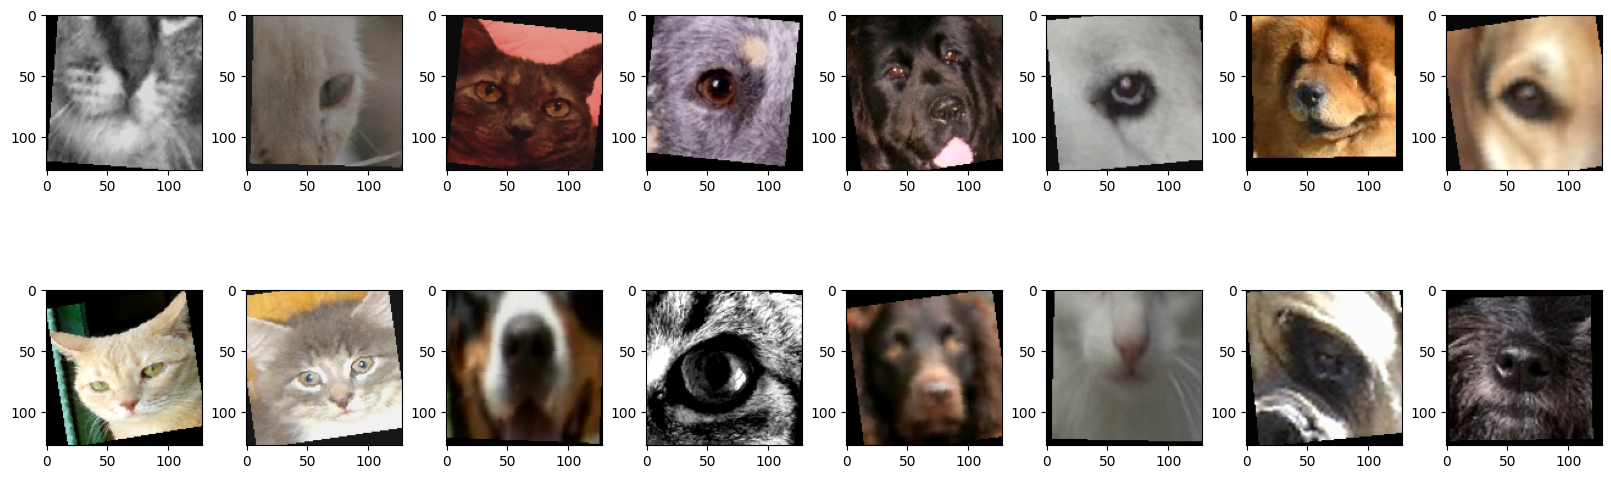

In [4]:
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

class FacialFeatureDataset(Dataset):
    """Loads images on demand. Returns (image, label) for train/val, (image, image_id) for test."""
    def __init__(self, df, img_dir, transform, has_labels=True):
        self.ids = df["image_id"].values
        self.labels = df["label"].values if has_labels else None
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        img_id = int(self.ids[idx])
        path = os.path.join(self.img_dir, f"{img_id:05d}.jpg")
        img = Image.open(path).convert("RGB")     # safety net: always 3 channels
        img = self.transform(img)
        if self.labels is not None:
            return img, int(self.labels[idx])
        return img, img_id

# Test set: use sample_submission order so predictions line up with the required IDs
test_df = pd.read_csv(os.path.join(BASE, "sample_submission.csv"))[["image_id"]]

train_ds = FacialFeatureDataset(train_df, TRAIN_DIR, train_tf)
val_ds   = FacialFeatureDataset(val_df,   TRAIN_DIR, eval_tf)
test_ds  = FacialFeatureDataset(test_df,  TEST_DIR,  eval_tf, has_labels=False)

g = torch.Generator().manual_seed(SEED)   # makes the shuffling order reproducible
loader_args = dict(batch_size=CFG["batch_size"], num_workers=CFG["num_workers"], pin_memory=True)

train_loader = DataLoader(train_ds, shuffle=True, drop_last=True, generator=g, **loader_args)
val_loader   = DataLoader(val_ds,   shuffle=False, **loader_args)
test_loader  = DataLoader(test_ds,  shuffle=False, **loader_args)

print(f"Train: {len(train_ds)} images, {len(train_loader)} batches")
print(f"Val:   {len(val_ds)} images, {len(val_loader)} batches")
print(f"Test:  {len(test_ds)} images, {len(test_loader)} batches")

# Visual check: grab one batch, then close the temporary loader cleanly
it = iter(train_loader)
imgs, lbls = next(it)
del it
print("Batch tensor shape:", imgs.shape)   # expect [128, 3, 224, 224]

mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 8, figsize=(16, 5.5), constrained_layout=True)
for ax, img, lbl in zip(axes.flat, imgs[:16], lbls[:16]):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))

In [5]:
import timm

MODEL_NAME = "tf_efficientnetv2_s"
model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(CLASSES))
model = model.to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"timm version: {timm.__version__}")
print(f"Model: {MODEL_NAME} | parameters: {n_params/1e6:.1f}M")
print("Classifier head:", model.get_classifier())

# Sanity check: one forward pass on the batch from Cell 4
model.eval()
with torch.no_grad():
    out = model(imgs[:8].to(device))
print("Output shape:", out.shape)   # expect [8, 8]: 8 images x 8 class scores

model.safetensors: reconstructing file:   0%|          |  0.00B / 86.5MB            

model.safetensors: downloading bytes:           |  0.00B            

timm version: 1.0.29
Model: tf_efficientnetv2_s | parameters: 20.2M
Classifier head: Linear(in_features=1280, out_features=8, bias=True)
Output shape: torch.Size([8, 8])


Config: {'exp_name': 'effnetv2_s_128', 'img_size': 128, 'batch_size': 128, 'num_workers': 4, 'epochs': 8, 'lr': 0.0003, 'weight_decay': 0.05, 'label_smoothing': 0.1, 'warmup_epochs': 1}


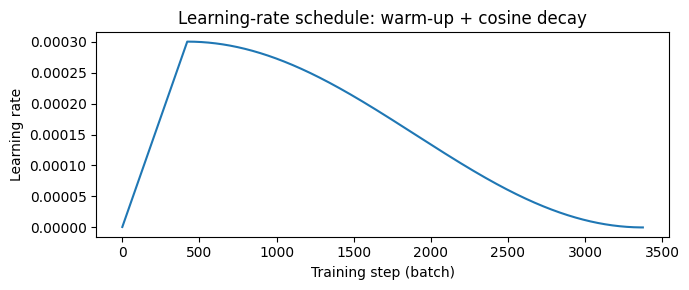

In [6]:
import math
import torch.nn as nn

CFG.update({
    "epochs": 8,
    "lr": 3e-4,
    "weight_decay": 0.05,
    "label_smoothing": 0.1,
    "warmup_epochs": 1,
})

# Loss: cross-entropy with label smoothing
criterion = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])

# Optimiser: AdamW
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])

# Learning-rate schedule: 1 epoch linear warm-up, then cosine decay to 0 (updated every batch)
steps_per_epoch = len(train_loader)
total_steps  = CFG["epochs"] * steps_per_epoch
warmup_steps = CFG["warmup_epochs"] * steps_per_epoch

def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

# Mixed precision: faster training on the T4 with almost no accuracy cost
scaler = torch.amp.GradScaler("cuda")

print("Config:", CFG)

# Plot the schedule (useful figure for the report)
plt.figure(figsize=(7, 3))
plt.plot([CFG["lr"] * lr_lambda(s) for s in range(total_steps)])
plt.title("Learning-rate schedule: warm-up + cosine decay")
plt.xlabel("Training step (batch)"); plt.ylabel("Learning rate")
plt.tight_layout(); plt.show()

In [7]:
import warnings
warnings.filterwarnings("ignore", message="Detected call of `lr_scheduler.step\\(\\)` before `optimizer.step\\(\\)`")
import time
from tqdm.auto import tqdm

def train_one_epoch(model, loader):
    model.train()                                   # enables dropout/stochastic depth
    total_loss, correct, n = 0.0, 0, 0
    for x, y in tqdm(loader, desc="train", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)       # clear old gradients
        with torch.autocast("cuda", dtype=torch.float16):   # mixed precision
            logits = model(x)
            loss = criterion(logits, y)
        scaler.scale(loss).backward()               # backpropagation
        scaler.step(optimizer)                      # update weights
        scaler.update()
        scheduler.step()                            # update learning rate (per batch)
        total_loss += loss.item() * x.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n

@torch.no_grad()                                    # no gradients needed for evaluation
def evaluate(model, loader):
    model.eval()                                    # disables dropout etc.
    total_loss, correct, n = 0.0, 0, 0
    all_preds, all_labels = [], []
    for x, y in tqdm(loader, desc="val", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x)
            loss = criterion(logits, y)
        preds = logits.argmax(1)
        total_loss += loss.item() * x.size(0)
        correct += (preds == y).sum().item()
        n += x.size(0)
        all_preds.append(preds.cpu()); all_labels.append(y.cpu())
    return total_loss / n, correct / n, torch.cat(all_preds), torch.cat(all_labels)

# ---- Training with checkpointing and early stopping ----
CKPT_PATH = f"/kaggle/working/best_{CFG['exp_name']}.pth"
PATIENCE = 3
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_acc, epochs_no_improve = 0.0, 0

for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    va_loss, va_acc, _, _ = evaluate(model, val_loader)

    for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc]):
        history[k].append(v)

    print(f"Epoch {epoch}/{CFG['epochs']} | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
          f"{time.time() - t0:.0f}s")

    if va_acc > best_acc:                           # save only when validation improves
        best_acc, epochs_no_improve = va_acc, 0
        torch.save(model.state_dict(), CKPT_PATH)
        print(f"  -> new best val acc {best_acc:.4f}, checkpoint saved")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping: no improvement for {PATIENCE} epochs")
            break

print(f"\nBest validation accuracy: {best_acc:.4f}")

train:   0%|          | 0/422 [00:00<?, ?it/s]

val:   0%|          | 0/75 [00:00<?, ?it/s]

Epoch 1/8 | train loss 2.1216 acc 0.7160 | val loss 0.6451 acc 0.9495 | 151s
  -> new best val acc 0.9495, checkpoint saved


train:   0%|          | 0/422 [00:00<?, ?it/s]

val:   0%|          | 0/75 [00:00<?, ?it/s]

...

Epoch 7/8 | train loss 0.4899 acc 0.9942 | val loss 0.4890 acc 0.9939 | 134s
  -> new best val acc 0.9939, checkpoint saved


train:   0%|          | 0/422 [00:00<?, ?it/s]

val:   0%|          | 0/75 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x785f7fe0eca0><function _MultiProcessingDataLoaderIter.__del__ at 0x785f7fe0eca0>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()
self._shutdown_workers()  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
if w.is_alive():    
if w.is_alive():  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a

Epoch 8/8 | train loss 0.4882 acc 0.9950 | val loss 0.4885 acc 0.9946 | 133s
  -> new best val acc 0.9946, checkpoint saved

Best validation accuracy: 0.9946


       train_loss  train_acc  val_loss  val_acc
epoch                                          
1          2.1216     0.7160    0.6451   0.9495
2          0.5821     0.9702    0.5419   0.9828
3          0.5275     0.9857    0.5141   0.9880
4          0.5091     0.9894    0.4981   0.9925
5          0.4990     0.9920    0.4929   0.9935
6          0.4928     0.9936    0.4914   0.9936
7          0.4899     0.9942    0.4890   0.9939
8          0.4882     0.9950    0.4885   0.9946


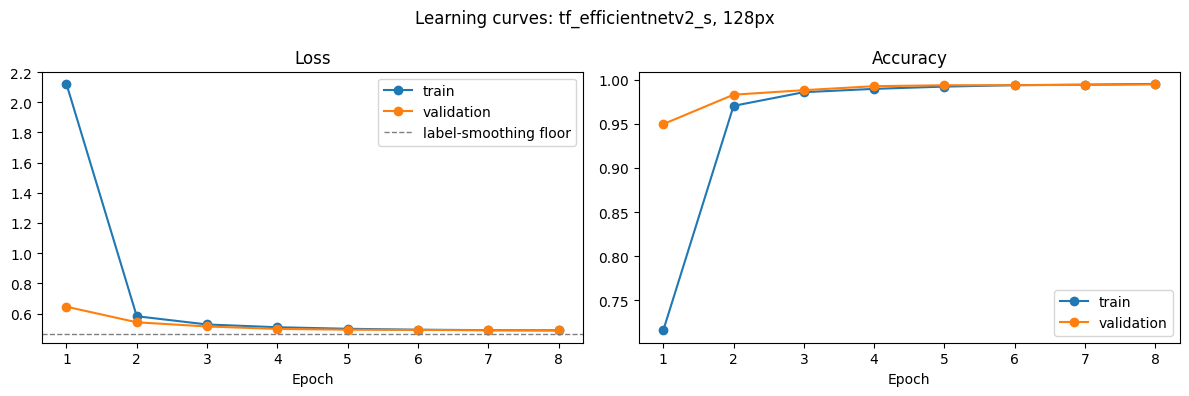

In [8]:
hist_df = pd.DataFrame(history)
hist_df.index = range(1, len(hist_df) + 1)
hist_df.index.name = "epoch"
print(hist_df.round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(hist_df.index, hist_df["train_loss"], "o-", label="train")
ax1.plot(hist_df.index, hist_df["val_loss"], "o-", label="validation")
ax1.axhline(0.467, color="grey", ls="--", lw=1, label="label-smoothing floor")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(hist_df.index, hist_df["train_acc"], "o-", label="train")
ax2.plot(hist_df.index, hist_df["val_acc"], "o-", label="validation")
ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.legend()

plt.suptitle(f"Learning curves: {MODEL_NAME}, {CFG['img_size']}px")
plt.tight_layout(); plt.show()

hist_df.to_csv(f"/kaggle/working/history_{CFG['exp_name']}.csv")   # keep for the experiments table

val:   0%|          | 0/75 [00:00<?, ?it/s]

Best checkpoint -> val loss 0.4885 | val acc 0.9946

              precision    recall  f1-score   support

      CatEye     0.9971    0.9938    0.9954      2082
     CatFace     1.0000    1.0000    1.0000      1041
    CatMouth     0.9820    0.9942    0.9881      1041
     CatNose     0.9884    0.9789    0.9836      1041
      DogEye     0.9937    0.9942    0.9940      1736
     DogFace     0.9988    1.0000    0.9994       868
    DogMouth     0.9977    1.0000    0.9989       869
     DogNose     0.9988    0.9988    0.9988       869

    accuracy                         0.9946      9547
   macro avg     0.9946    0.9950    0.9948      9547
weighted avg     0.9946    0.9946    0.9946      9547



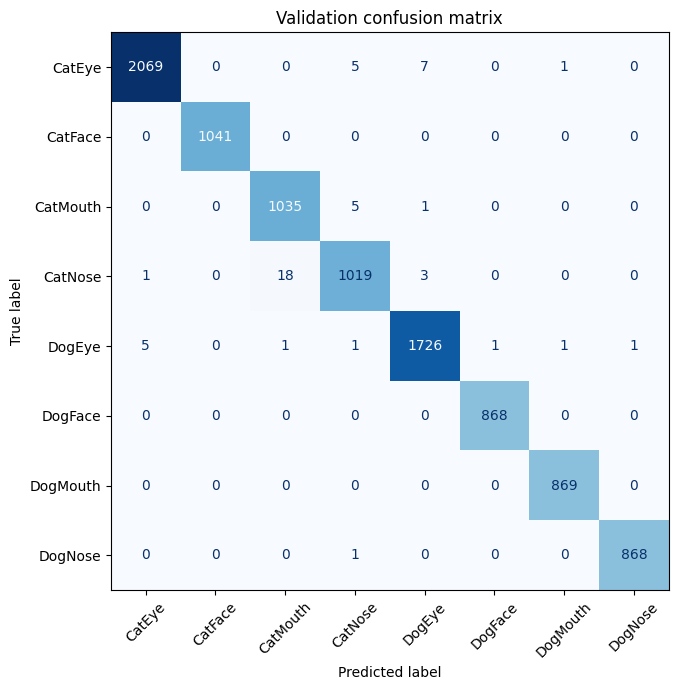

Misclassified: 52 of 9547


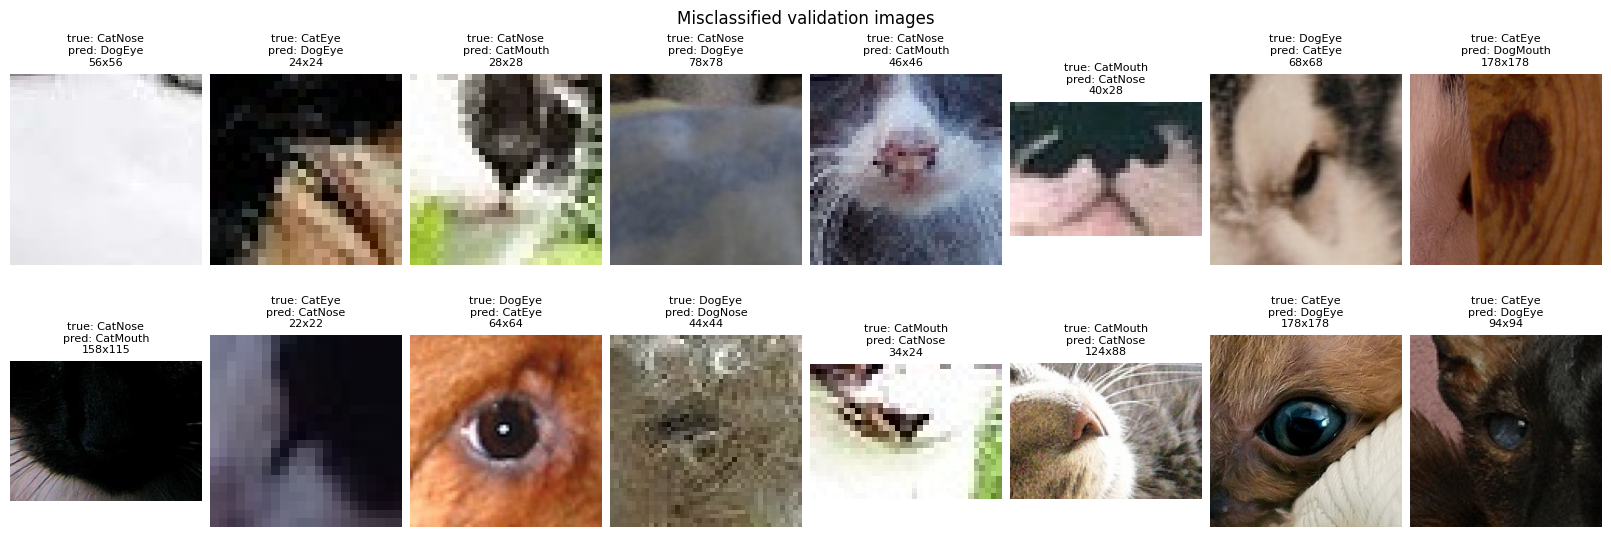

In [9]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Load the BEST checkpoint (not just the last epoch's weights)
model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
va_loss, va_acc, val_preds, val_labels = evaluate(model, val_loader)
print(f"Best checkpoint -> val loss {va_loss:.4f} | val acc {va_acc:.4f}\n")

# Per-class precision, recall, F1
print(classification_report(val_labels, val_preds, target_names=CLASSES, digits=4))

# Confusion matrix
cm = confusion_matrix(val_labels, val_preds)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues",
                                                        xticks_rotation=45, colorbar=False)
ax.set_title("Validation confusion matrix")
plt.tight_layout(); plt.show()

# Show the misclassified images (original, un-augmented)
wrong = np.where(val_preds.numpy() != val_labels.numpy())[0]
print(f"Misclassified: {len(wrong)} of {len(val_df)}")
n_show = min(16, len(wrong))
fig, axes = plt.subplots(2, 8, figsize=(16, 5.5), constrained_layout=True)
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, wrong[:n_show]):
    img_id = int(val_df.iloc[i]["image_id"])
    img = Image.open(os.path.join(TRAIN_DIR, f"{img_id:05d}.jpg"))
    ax.imshow(img)
    ax.set_title(f"true: {CLASSES[val_labels[i]]}\npred: {CLASSES[val_preds[i]]}\n{img.size[0]}x{img.size[1]}",
                 fontsize=8)
fig.suptitle("Misclassified validation images")
plt.show()

In [10]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    all_preds, all_ids = [], []
    for x, img_ids in tqdm(loader, desc="test"):
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x.to(device, non_blocking=True))
        all_preds.append(logits.argmax(1).cpu())
        all_ids.append(img_ids)
    return torch.cat(all_preds).numpy(), torch.cat(all_ids).numpy()

test_preds, test_ids = predict(model, test_loader)

# Build the submission in the exact sample_submission format
sub = pd.read_csv(os.path.join(BASE, "sample_submission.csv"))
assert (sub["image_id"].values == test_ids).all(), "ID order mismatch!"
sub["class"] = [idx_to_class[p] for p in test_preds]

# Safety checks before submitting
assert len(sub) == 29443
assert set(sub["class"]).issubset(set(CLASSES))
assert sub["image_id"].is_unique

SUB_PATH = f"/kaggle/working/submission_{CFG['exp_name']}.csv"
sub.to_csv(SUB_PATH, index=False)
print(sub.head())
print("\nPredicted class distribution:\n", sub["class"].value_counts())
print(f"\nSaved {SUB_PATH}")

test:   0%|          | 0/231 [00:00<?, ?it/s]

   image_id     class
0         1    DogEye
1         2  DogMouth
2         3   DogNose
3         4   DogFace
4         5  CatMouth

Predicted class distribution:
 class
CatEye      6371
DogEye      5522
CatMouth    3265
CatFace     3126
CatNose     2887
DogMouth    2822
DogFace     2803
DogNose     2647
Name: count, dtype: int64

Saved /kaggle/working/submission_effnetv2_s_128.csv
